# Natural Language Processing – Review Analytics from Raw Text to Streamlit App

Steps:
1. NLP fundamentals, text preprocessing and Regular Expressions
2. Feature extraction: Bag of Words, TF-IDF and N-Grams
3. Word embeddings: Word2Vec (CBOW and Skip-gram)
4. Text classification pipeline – sentiment analysis
5. Different NLP approaches and POS tagging
6. Build and deploy an NLP project using Streamlit
7. Comparison, reflection and GitHub submission


In [41]:
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset


from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
MODEL_DIR = Path("models")
for d in (DATA_DIR, OUTPUT_DIR, MODEL_DIR):
    d.mkdir(exist_ok=True)

imdb_path = DATA_DIR / "IMDB Dataset.csv"
sms_path = DATA_DIR / "spam.csv"

print("Python:", sys.version)
print("Working directory:", Path.cwd())
print("Data folder:", DATA_DIR.resolve())



ds = load_dataset("stanfordnlp/imdb")          # 25k train + 25k test labelled reviews
df = pd.concat([ds["train"].to_pandas(), ds["test"].to_pandas()], ignore_index=True)
df["sentiment"] = df["label"].map({0: "negative", 1: "positive"})
df = df.rename(columns={"text": "review"})[["review", "sentiment"]]

df.to_csv(imdb_path, index=False, encoding="utf-8")
print(df.shape, "->", imdb_path)
print(df["sentiment"].value_counts())

Python: 3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]
Working directory: d:\NLP
Data folder: D:\NLP\data


(50000, 2) -> data\IMDB Dataset.csv
sentiment
negative    25000
positive    25000
Name: count, dtype: int64


## Step 1 – NLP Fundamentals, Text Preprocessing and Regular Expressions

### 1.1 Dataset overview
- **SMS Spam Collection:** messages labelled `ham` or `spam` (a separate classification corpus, not sentiment).
- **IMDb Movie Reviews:** reviews labelled `positive` or `negative`.

The loaders below try several encodings and check the columns, so a wrong or misnamed file gives a clear message instead of a crash.

In [42]:
def read_csv_safe(path, **kwargs):
    """Read a CSV, trying UTF-8 first and then Latin-1."""
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc, **kwargs)
        except UnicodeDecodeError:
            continue
    raise UnicodeDecodeError("Could not decode " + str(path))

def load_imdb(path):
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Put 'IMDB Dataset.csv' in the data folder.")
    df = read_csv_safe(path)
    if {"review", "sentiment"}.issubset(df.columns):
        df = df[["review", "sentiment"]].dropna().copy()
        df["sentiment"] = df["sentiment"].astype(str).str.lower().str.strip()
        return df
    if {"v1", "v2"}.issubset(df.columns):
        raise ValueError(
            f"'{path.name}' has columns v1/v2, so it is the SMS spam file, not the IMDb reviews. "
            "Rename it to spam.csv and download the real IMDb file from Kaggle "
            "('IMDB Dataset of 50K Movie Reviews')."
        )
    raise ValueError(f"'{path.name}' has columns {df.columns.tolist()}; expected 'review' and 'sentiment'.")

def load_sms(path):
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Put 'spam.csv' in the data folder.")
    df = read_csv_safe(path)
    if {"v1", "v2"}.issubset(df.columns):
        df = df.rename(columns={"v1": "label", "v2": "text"})
    elif {"label", "message"}.issubset(df.columns):
        df = df.rename(columns={"message": "text"})
    else:
        raise ValueError(f"'{path.name}' has columns {df.columns.tolist()}; expected v1/v2 or label/message.")
    return df[["label", "text"]].dropna().copy()

# Quick report on every CSV in the data folder
for p in sorted(DATA_DIR.glob("*.csv")):
    head = read_csv_safe(p, nrows=3)
    print(f"{p.name:22s} {p.stat().st_size // 1024:>7} KB  columns: {head.columns.tolist()}")

IMDB Dataset.csv         64709 KB  columns: ['review', 'sentiment']
spam.csv                   491 KB  columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


In [43]:
imdb_df, sms_df = None, None

try:
    imdb_df = load_imdb(imdb_path)
    print("IMDb shape:", imdb_df.shape)
    display(imdb_df.head())
except (FileNotFoundError, ValueError) as e:
    print("IMDb problem:", e)

try:
    sms_df = load_sms(sms_path)
    print("SMS shape:", sms_df.shape)
    display(sms_df.head())
except (FileNotFoundError, ValueError) as e:
    print("SMS problem:", e)

IMDb shape: (50000, 2)


,review,sentiment
0,I rented I AM CURIOUS-YELLOW from my video sto...,negative
1,"""I Am Curious: Yellow"" is a risible and preten...",negative
2,If only to avoid making this type of film in t...,negative
3,This film was probably inspired by Godard's Ma...,negative
4,"Oh, brother...after hearing about this ridicul...",negative


SMS shape: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### 1.2 Explore and inspect the datasets

IMDb missing values:
 review       0
sentiment    0
dtype: int64

IMDb class distribution:
 sentiment
negative    25000
positive    25000
Name: count, dtype: int64


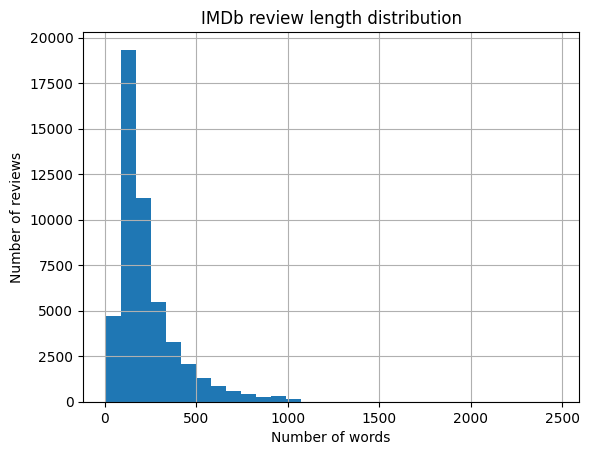


SMS class distribution:
 label
ham     4825
spam     747
Name: count, dtype: int64


In [44]:
if imdb_df is not None:
    print("IMDb missing values:\n", imdb_df.isnull().sum())
    print("\nIMDb class distribution:\n", imdb_df["sentiment"].value_counts())
    imdb_df["review_length"] = imdb_df["review"].astype(str).str.split().str.len()
    imdb_df["review_length"].hist(bins=30)
    plt.title("IMDb review length distribution")
    plt.xlabel("Number of words")
    plt.ylabel("Number of reviews")
    plt.show()

if sms_df is not None:
    print("\nSMS class distribution:\n", sms_df["label"].value_counts())

### 1.3 Regular Expressions (RegEx)

In [45]:
sample_messages = [
    "Visit https://example.com for details!",
    "Contact student@example.com today.",
    "Call +91 9876543210 for support.",
    "I ordered 3 items for Rs. 500."
]

url_pattern = r"https?://\S+|www\.\S+"
email_pattern = r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b"
phone_pattern = r"\b(?:\+?\d[\d\s().-]{7,}\d)\b"
number_pattern = r"\b\d+\b"

for msg in sample_messages:
    print("\nMessage:", msg)
    print("URLs:", re.findall(url_pattern, msg, flags=re.I))
    print("Emails:", re.findall(email_pattern, msg))
    print("Phone numbers:", re.findall(phone_pattern, msg))
    print("Numbers:", re.findall(number_pattern, msg))


Message: Visit https://example.com for details!
URLs: ['https://example.com']
Emails: []
Phone numbers: []
Numbers: []

Message: Contact student@example.com today.
URLs: []
Emails: ['student@example.com']
Phone numbers: []
Numbers: []

Message: Call +91 9876543210 for support.
URLs: []
Emails: []
Phone numbers: ['91 9876543210']
Numbers: ['91', '9876543210']

Message: I ordered 3 items for Rs. 500.
URLs: []
Emails: []
Phone numbers: []
Numbers: ['3', '500']


### 1.4 Text preprocessing pipeline
Replacement tokens are lowercase (`url`, `email`, ...) so they survive the later "letters only" step. HTML tags such as `<br />` (common in IMDb) are removed too.

In [46]:
def clean_text(text):
    """Normalize text and replace variable patterns with placeholder tokens."""
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)                          # HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " urltoken ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b", " emailtoken ", text)
    text = re.sub(r"\b(?:\+?\d[\d\s().-]{7,}\d)\b", " phonetoken ", text)
    text = re.sub(r"\b\d+\b", " numbertoken ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize(text):
    return clean_text(text).split()

for msg in sample_messages:
    print(msg, " -> ", clean_text(msg))

Visit https://example.com for details!  ->  visit urltoken for details
Contact student@example.com today.  ->  contact emailtoken today
Call +91 9876543210 for support.  ->  call phonetoken for support
I ordered 3 items for Rs. 500.  ->  i ordered numbertoken items for rs numbertoken


### 1.5 Stopword removal and stemming vs. lemmatization

In [47]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

for resource in ["stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(resource, quiet=True)
    except Exception as e:
        print("Could not download", resource, e)

try:
    stop_words = set(stopwords.words("english"))
except LookupError:
    stop_words = set()

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

example_words = ["playing", "studies", "cars", "better", "running"]
print("Word | Stem | Lemma")
for word in example_words:
    try:
        lemma = lemmatizer.lemmatize(word)
    except LookupError:
        lemma = word
    print(word, "|", stemmer.stem(word), "|", lemma)

def preprocess_tokens(text, remove_stopwords=True):
    tokens = tokenize(text)
    if remove_stopwords and stop_words:
        tokens = [t for t in tokens if t not in stop_words]
    return tokens

example_text = "This movie was very good and the actors were playing wonderfully."
print("Tokens:", tokenize(example_text))
print("Without stopwords:", preprocess_tokens(example_text))

Word | Stem | Lemma
playing | play | playing
studies | studi | study
cars | car | car
better | better | better
running | run | running
Tokens: ['this', 'movie', 'was', 'very', 'good', 'and', 'the', 'actors', 'were', 'playing', 'wonderfully']
Without stopwords: ['movie', 'good', 'actors', 'playing', 'wonderfully']


## Step 2 – Feature Extraction: Bag of Words, TF-IDF and N-Grams
A small five-sentence corpus first, so matrices and vocabulary are easy to inspect.

In [48]:
tiny_corpus = [
    "The movie was good and the acting was excellent",
    "The movie was bad but the music was good",
    "The acting was excellent and the story was wonderful",
    "This product is bad and delivery was slow",
    "I love this product it is excellent"
]
tiny_clean = [clean_text(x) for x in tiny_corpus]

bow = CountVectorizer()
bow_matrix = bow.fit_transform(tiny_clean)
print("Bag of Words vocabulary:", bow.get_feature_names_out().tolist())
display(pd.DataFrame(bow_matrix.toarray(), columns=bow.get_feature_names_out()))

tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(tiny_clean)
display(pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf.get_feature_names_out()).round(3))

ngram = CountVectorizer(ngram_range=(1, 2))
ngram_matrix = ngram.fit_transform(tiny_clean)
print("Unigram + bigram features:", ngram.get_feature_names_out().tolist())
display(pd.DataFrame(ngram_matrix.toarray(), columns=ngram.get_feature_names_out()))

Bag of Words vocabulary: ['acting', 'and', 'bad', 'but', 'delivery', 'excellent', 'good', 'is', 'it', 'love', 'movie', 'music', 'product', 'slow', 'story', 'the', 'this', 'was', 'wonderful']


,acting,and,bad,but,delivery,excellent,good,is,it,love,movie,music,product,slow,story,the,this,was,wonderful
0,1,1,0,0,0,1,1,0,0,0,1,0,0,0,0,2,0,2,0
1,0,0,1,1,0,0,1,0,0,0,1,1,0,0,0,2,0,2,0
2,1,1,0,0,0,1,0,0,0,0,0,0,0,0,1,2,0,2,1
3,0,1,1,0,1,0,0,1,0,0,0,0,1,1,0,0,1,1,0
4,0,0,0,0,0,1,0,1,1,1,0,0,1,0,0,0,1,0,0


,acting,and,bad,but,delivery,excellent,good,is,it,love,movie,music,product,slow,story,the,this,was,wonderful
0,0.332,0.275,0.000,0.000,0.000,0.275,0.332,0.000,0.000,0.000,0.332,0.000,0.000,0.000,0.000,0.551,0.000,0.463,0.000
1,0.000,0.000,0.305,0.378,0.000,0.000,0.305,0.000,0.000,0.000,0.305,0.378,0.000,0.000,0.000,0.506,0.000,0.425,0.000
2,0.314,0.260,0.000,0.000,0.000,0.260,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.389,0.521,0.000,0.438,0.389
3,0.000,0.289,0.348,0.000,0.432,0.000,0.000,0.348,0.000,0.000,0.000,0.000,0.348,0.432,0.000,0.000,0.348,0.243,0.000
4,0.000,0.000,0.000,0.000,0.000,0.319,0.000,0.385,0.477,0.477,0.000,0.000,0.385,0.000,0.000,0.000,0.385,0.000,0.000


Unigram + bigram features: ['acting', 'acting was', 'and', 'and delivery', 'and the', 'bad', 'bad and', 'bad but', 'but', 'but the', 'delivery', 'delivery was', 'excellent', 'excellent and', 'good', 'good and', 'is', 'is bad', 'is excellent', 'it', 'it is', 'love', 'love this', 'movie', 'movie was', 'music', 'music was', 'product', 'product is', 'product it', 'slow', 'story', 'story was', 'the', 'the acting', 'the movie', 'the music', 'the story', 'this', 'this product', 'was', 'was bad', 'was excellent', 'was good', 'was slow', 'was wonderful', 'wonderful']


,acting,acting was,and,and delivery,and the,bad,bad and,bad but,but,but the,...,the story,this,this product,was,was bad,was excellent,was good,was slow,was wonderful,wonderful
0,1,1,1,0,1,0,0,0,0,0,...,0,0,0,2,0,1,1,0,0,0
1,0,0,0,0,0,1,0,1,1,1,...,0,0,0,2,1,0,1,0,0,0
2,1,1,1,0,1,0,0,0,0,0,...,1,0,0,2,0,1,0,0,1,1
3,0,0,1,1,0,1,1,0,0,0,...,0,1,1,1,0,0,0,1,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,1,1,0,0,0,0,0,0,0


### 2.1 Feature extraction on the SMS corpus
Prints matrix shapes and the most frequent terms.

In [49]:
if sms_df is not None:
    sms_work = sms_df.copy()
    sms_work["clean_text"] = sms_work["text"].map(clean_text)

    sms_bow = CountVectorizer(max_features=3000)
    sms_bow_matrix = sms_bow.fit_transform(sms_work["clean_text"])
    print("SMS BoW matrix:", sms_bow_matrix.shape)
    counts = np.asarray(sms_bow_matrix.sum(axis=0)).ravel()
    top_bow = pd.DataFrame({"term": sms_bow.get_feature_names_out(), "count": counts})
    display(top_bow.sort_values("count", ascending=False).head(15))

    sms_tfidf = TfidfVectorizer(max_features=3000)
    sms_tfidf_matrix = sms_tfidf.fit_transform(sms_work["clean_text"])
    print("SMS TF-IDF matrix:", sms_tfidf_matrix.shape)
else:
    print("Add data/spam.csv to run the SMS corpus analysis.")

SMS BoW matrix: (5572, 3000)


,term,count
1721,numbertoken,2515
2987,you,2243
2654,to,2242
2601,the,1332
90,and,979
1244,in,902
1283,is,890
1538,me,802
1657,my,762
1291,it,747


SMS TF-IDF matrix: (5572, 3000)


## Step 3 – Word Embeddings: Word2Vec (CBOW and Skip-gram)
- **CBOW** predicts a target word from its context.
- **Skip-gram** predicts context words from a target word.

In [50]:
if imdb_df is not None:
    from gensim.models import Word2Vec

    sample_reviews = imdb_df["review"].astype(str).sample(
        min(5000, len(imdb_df)), random_state=RANDOM_STATE
    )
    tokenized_reviews = [tokenize(r) for r in sample_reviews]

    cbow_model = Word2Vec(sentences=tokenized_reviews, vector_size=100, window=5,
                          min_count=2, workers=4, sg=0, seed=RANDOM_STATE, epochs=10)
    skipgram_model = Word2Vec(sentences=tokenized_reviews, vector_size=100, window=5,
                              min_count=2, workers=4, sg=1, seed=RANDOM_STATE, epochs=10)

    cbow_model.save(str(MODEL_DIR / "word2vec_cbow.model"))
    skipgram_model.save(str(MODEL_DIR / "word2vec_skipgram.model"))

    for model_name, model in [("CBOW", cbow_model), ("Skip-gram", skipgram_model)]:
        print("\n", model_name)
        if "movie" in model.wv:
            display(pd.DataFrame(model.wv.most_similar("movie", topn=10),
                                 columns=["similar_word", "similarity"]))
        else:
            print("'movie' is not in this model's vocabulary.")
else:
    print("Load the IMDb data (Step 1.1) before training Word2Vec.")


 CBOW


,similar_word,similarity
0,film,0.920934
1,show,0.726242
2,series,0.684711
3,flick,0.674564
4,picture,0.644467
5,sequel,0.636850
6,episode,0.628617
7,documentary,0.623936
8,thing,0.621441
9,mess,0.606611



 Skip-gram


,similar_word,similarity
0,film,0.905876
1,congratulations,0.753958
2,'b',0.741054
3,chore,0.739008
4,buzz,0.738500
5,flashdance,0.737547
6,fyi,0.735023
7,downer,0.733894
8,sketch,0.732048
9,sludge,0.729869


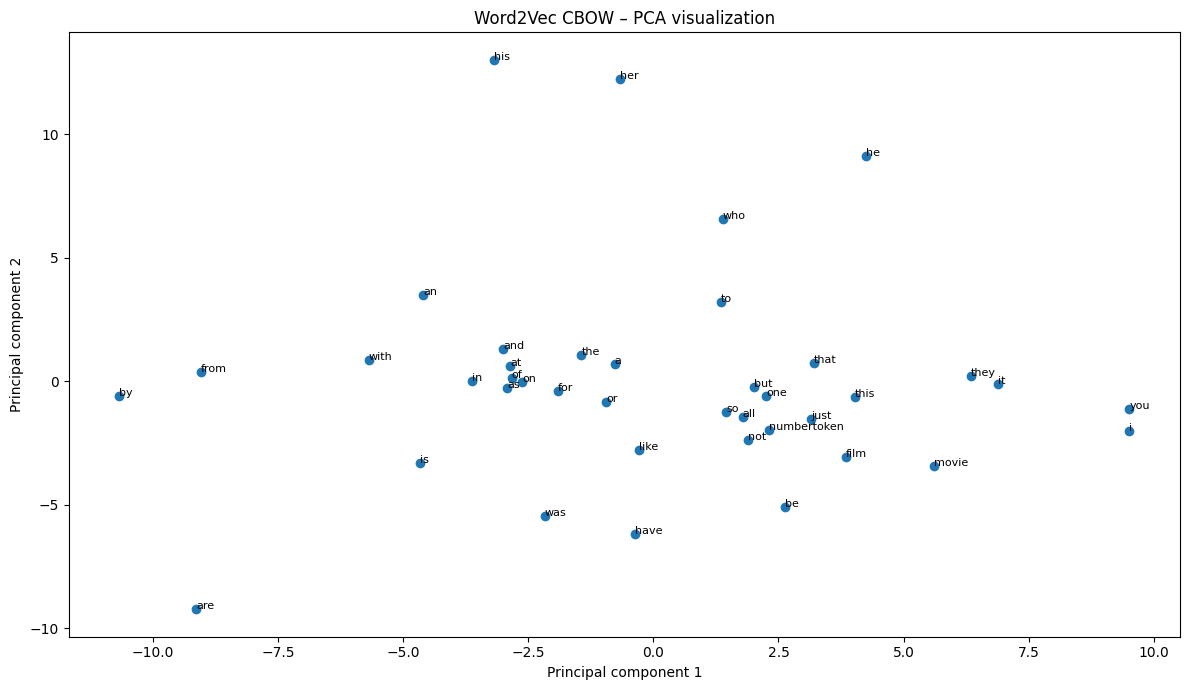

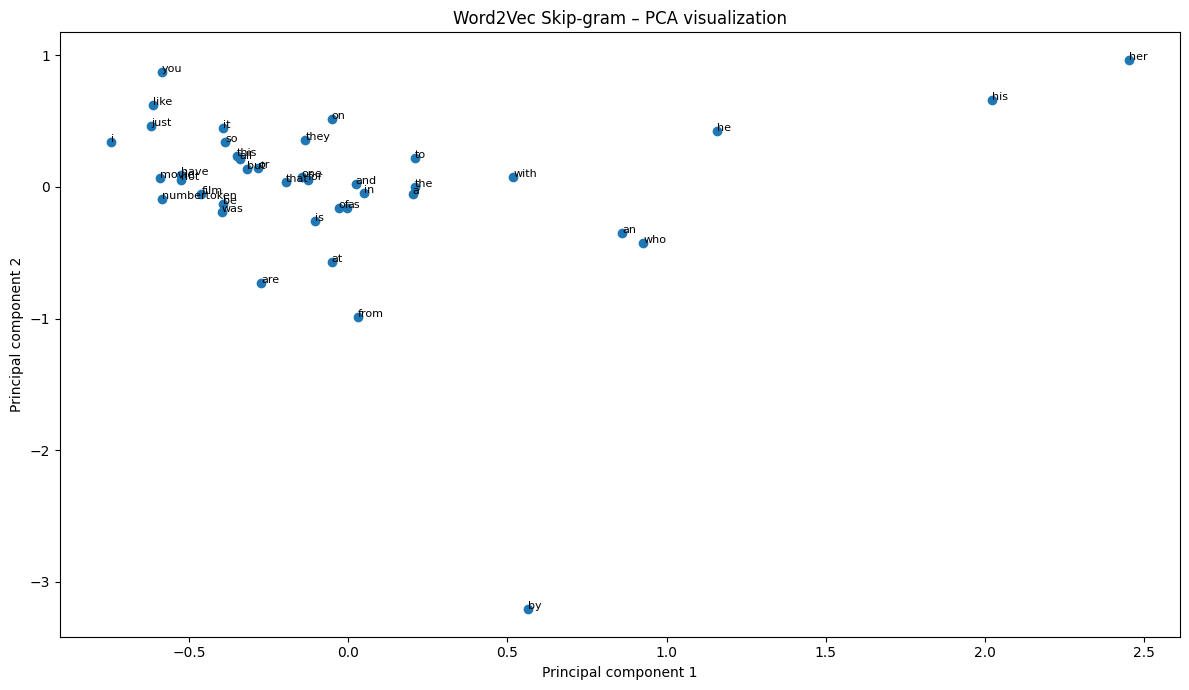

In [51]:
# PCA visualization of the 40 most frequent words in each model.
if imdb_df is not None:
    from sklearn.decomposition import PCA

    for model_name, model in [("CBOW", cbow_model), ("Skip-gram", skipgram_model)]:
        words = model.wv.index_to_key[:40]
        vectors = np.array([model.wv[w] for w in words])
        coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(vectors)

        plt.figure(figsize=(12, 7))
        plt.scatter(coords[:, 0], coords[:, 1])
        for word, (x, y) in zip(words, coords):
            plt.annotate(word, (x, y), fontsize=8)
        plt.title(f"Word2Vec {model_name} – PCA visualization")
        plt.xlabel("Principal component 1")
        plt.ylabel("Principal component 2")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f"word2vec_{model_name.lower()}_pca.png", dpi=160)
        plt.show()

## Step 4 – Text Classification Pipeline: Sentiment Analysis
IMDb binary sentiment classification with four models: Multinomial Naive Bayes, Logistic Regression, Linear SVM, Random Forest. Metrics: accuracy, precision, recall, weighted F1.

In [52]:
imdb_df = load_imdb(imdb_path)
print(imdb_df.shape)

if imdb_df is None:
    raise RuntimeError("IMDb data not loaded. Fix Step 1.1 first (see the message printed there).")

imdb = imdb_df[["review", "sentiment"]].copy()
imdb["clean_text"] = imdb["review"].astype(str).map(clean_text)

X_train, X_test, y_train, y_test = train_test_split(
    imdb["clean_text"], imdb["sentiment"],
    test_size=0.2, random_state=RANDOM_STATE, stratify=imdb["sentiment"]
)

print("Total rows:", len(imdb))
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))
print("\nTraining class distribution:\n", y_train.value_counts())

(50000, 2)
Total rows: 50000
Training rows: 40000 | Testing rows: 10000

Training class distribution:
 sentiment
positive    20000
negative    20000
Name: count, dtype: int64


In [53]:
models = {
    "Naive Bayes (TF-IDF)": Pipeline([
        ("features", TfidfVectorizer(max_features=20000, ngram_range=(1, 2))),
        ("classifier", MultinomialNB())
    ]),
    "Logistic Regression (TF-IDF)": Pipeline([
        ("features", TfidfVectorizer(max_features=30000, ngram_range=(1, 2))),
        ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ]),
    "Linear SVM (TF-IDF)": Pipeline([
        ("features", TfidfVectorizer(max_features=30000, ngram_range=(1, 2))),
        ("classifier", LinearSVC(class_weight="balanced"))
    ]),
    "Random Forest (BoW)": Pipeline([
        ("features", CountVectorizer(max_features=20000, ngram_range=(1, 2))),
        ("classifier", RandomForestClassifier(
            n_estimators=100, random_state=RANDOM_STATE,
            class_weight="balanced", n_jobs=-1
        ))
    ])
}

results = []
trained_models = {}
for name, pipeline in models.items():
    print("Training:", name)
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    trained_models[name] = pipeline
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "recall": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "f1_score": f1_score(y_test, predictions, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("f1_score", ascending=False)
display(results_df)
results_df.to_csv(OUTPUT_DIR / "imdb_model_comparison.csv", index=False)

best_model_name = results_df.iloc[0]["model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)
print("Best model:", best_model_name)
print(classification_report(y_test, best_predictions))

Training: Naive Bayes (TF-IDF)
Training: Logistic Regression (TF-IDF)
Training: Linear SVM (TF-IDF)
Training: Random Forest (BoW)


,model,accuracy,precision,recall,f1_score
2,Linear SVM (TF-IDF),0.9129,0.912943,0.9129,0.912898
1,Logistic Regression (TF-IDF),0.9091,0.909218,0.9091,0.909093
0,Naive Bayes (TF-IDF),0.8772,0.877351,0.8772,0.877188
3,Random Forest (BoW),0.8575,0.857510,0.8575,0.857499


Best model: Linear SVM (TF-IDF)
              precision    recall  f1-score   support

    negative       0.92      0.91      0.91      5000
    positive       0.91      0.92      0.91      5000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



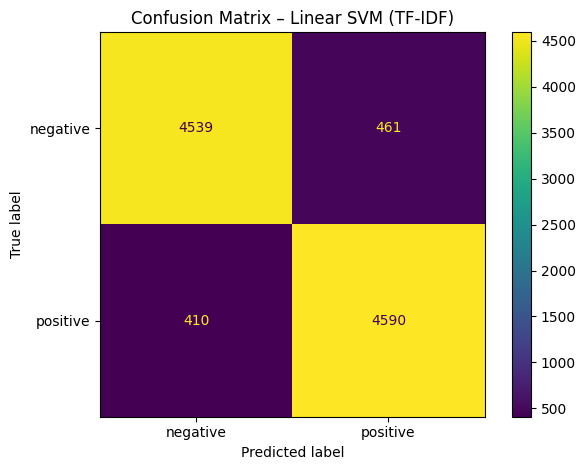

Saved: models\sentiment_pipeline.pkl


In [54]:
ConfusionMatrixDisplay.from_predictions(y_test, best_predictions)
plt.title(f"Confusion Matrix – {best_model_name}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=160)
plt.show()

import joblib
joblib.dump(best_model, MODEL_DIR / "sentiment_pipeline.pkl")
print("Saved:", MODEL_DIR / "sentiment_pipeline.pkl")

### 4.1 Test the trained model with new reviews

In [55]:
new_reviews = [
    "The movie was fantastic. The story and acting were excellent.",
    "This film was boring and a complete waste of time.",
    "The movie was released last week."
]
new_predictions = best_model.predict([clean_text(x) for x in new_reviews])
display(pd.DataFrame({"review": new_reviews, "predicted_sentiment": new_predictions}))

,review,predicted_sentiment
0,The movie was fantastic. The story and acting ...,positive
1,This film was boring and a complete waste of t...,negative
2,The movie was released last week.,positive


## Step 5 – Different NLP Approaches and POS Tagging
Compare a rule-based method, VADER, the trained ML model, and POS tagging with NLTK.

In [56]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

vader_analyzer = SentimentIntensityAnalyzer()

positive_words = {"good", "great", "excellent", "love", "loved", "amazing", "fast",
                  "happy", "best", "wonderful", "perfect", "brilliant"}
negative_words = {"bad", "worst", "poor", "hate", "awful", "slow",
                  "broken", "terrible", "disappointed", "waste", "boring"}

def rule_sentiment(text):
    words = set(re.findall(r"[a-z']+", str(text).lower()))
    score = len(words & positive_words) - len(words & negative_words)
    if score > 0:
        return "positive"
    if score < 0:
        return "negative"
    return "neutral"

def vader_sentiment(text):
    compound = vader_analyzer.polarity_scores(str(text))["compound"]
    if compound >= 0.05:
        return "positive"
    if compound <= -0.05:
        return "negative"
    return "neutral"

comparison_texts = [
    "I absolutely loved this movie. The acting was brilliant!",
    "This was a terrible experience and a waste of money.",
    "The film was released yesterday."
]

rows = []
for text in comparison_texts:
    rows.append({
        "text": text,
        "rule_based": rule_sentiment(text),
        "VADER": vader_sentiment(text),
        "ML_model": best_model.predict([clean_text(text)])[0]
    })
display(pd.DataFrame(rows))

,text,rule_based,VADER,ML_model
0,I absolutely loved this movie. The acting was ...,positive,positive,positive
1,This was a terrible experience and a waste of ...,negative,negative,negative
2,The film was released yesterday.,neutral,neutral,negative


In [57]:
# POS tagging
try:
    nltk.download("punkt", quiet=True)
    nltk.download("punkt_tab", quiet=True)
    nltk.download("averaged_perceptron_tagger_eng", quiet=True)
    from nltk import word_tokenize, pos_tag

    pos_text = "The excellent movie quickly captured the audience."
    display(pd.DataFrame(pos_tag(word_tokenize(pos_text)), columns=["word", "POS_tag"]))
except Exception as error:
    print("POS tagging resource issue:", error)

,word,POS_tag
0,The,DT
1,excellent,JJ
2,movie,NN
3,quickly,RB
4,captured,VBD
5,the,DT
6,audience,NN
7,.,.
